# Question 3: Embed-and-pool

We encode each sentence by pooling its glove vectors, combine the two sentence vectors as [u; v; |u−v|; u⊙v] and classify with an MLP. Same data and folds as Project 1 so results are directly comparable. Each variant changes one design choice compared to the base configuration (mean pooling, frozen embeddings, 1 hidden layer of 128, no dropout, lr 1e-3, 10 epochs).


In [5]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import baycomp

q3 = json.loads(Path("results/q3_glove.json").read_text())
p1 = json.loads(Path("../project1/results/tuning_results.json").read_text())

fasttext_path = Path("results/q3_fasttext.json")
q3_fasttext = json.loads(fasttext_path.read_text()) if fasttext_path.exists() else {}

MAJORITY_BASELINE = 0.558


**Results of all configurations compared to Project 1**


In [6]:
rows = []
for label, results in [("GloVe", q3), ("fastText", q3_fasttext)]:
    for name, r in results.items():
        acc = np.array(r["accuracies"])
        preds = np.array(r["predictions"])
        rows.append({
            "System": f"Q3 {label} {name}",
            "Mean accuracy": acc.mean() * 100,
            "Std over folds": acc.std(ddof=1) * 100,
            "Predicted paraphrase (%)": (preds == 1).mean() * 100,
        })
for name in ["indicator_deepmlp", "bow_deepmlp", "sentencetransformer_deepmlp"]:
    acc = np.array(p1[name]["accuracies"])
    rows.append({
        "System": f"P1 {name}",
        "Mean accuracy": acc.mean() * 100,
        "Std over folds": acc.std(ddof=1) * 100,
        "Predicted paraphrase (%)": np.nan,
    })
rows.append({"System": "Majority baseline", "Mean accuracy": MAJORITY_BASELINE * 100,
             "Std over folds": np.nan, "Predicted paraphrase (%)": 0.0})

results_df = pd.DataFrame(rows).sort_values("Mean accuracy", ascending=False).reset_index(drop=True)
display(results_df.round(2))


,System,Mean accuracy,Std over folds,Predicted paraphrase (%)
0,P1 indicator_deepmlp,58.70,0.65,NaN
1,P1 bow_deepmlp,58.39,0.70,NaN
2,P1 sentencetransformer_deepmlp,58.08,0.77,NaN
3,Q3 fastText base,56.47,0.90,17.18
4,Q3 GloVe pool_max,56.41,0.63,10.15
5,Q3 GloVe lr3e-3,56.18,0.54,17.84
6,Q3 GloVe pool_sum,55.98,0.08,1.80
7,Q3 GloVe base,55.98,0.77,17.10
8,Q3 GloVe hidden256_2layers,55.96,0.72,15.76
9,Q3 GloVe combine_concat,55.92,0.55,11.94


**Training loss and validation accuracy per epoch**


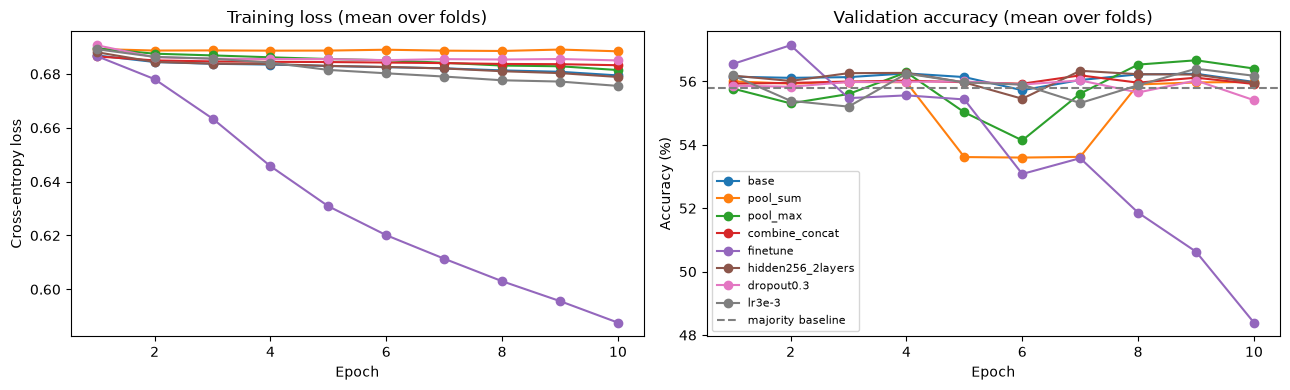

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, r in q3.items():
    val = np.array([[h["val_accuracy"] for h in fold] for fold in r["histories"]]).mean(axis=0)
    loss = np.array([[h["train_loss"] for h in fold] for fold in r["histories"]]).mean(axis=0)
    epochs = np.arange(1, len(val) + 1)
    axes[0].plot(epochs, loss, marker="o", label=name)
    axes[1].plot(epochs, val * 100, marker="o", label=name)

axes[0].set_title("Training loss (mean over folds)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[1].axhline(MAJORITY_BASELINE * 100, color="grey", linestyle="--", label="majority baseline")
axes[1].set_title("Validation accuracy (mean over folds)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()


**Bayesian comparison with ROPE (±1%)**


In [8]:
def rope_compare(name_a, acc_a, name_b, acc_b, rope=0.01):
    p_a, p_equal, p_b = baycomp.two_on_single(np.array(acc_a), np.array(acc_b), rope=rope, runs=1)
    return {"A": name_a, "B": name_b, "P(A better)": p_a, "P(equal)": p_equal, "P(B better)": p_b}

best_q3 = max(q3, key=lambda n: q3[n]["mean_accuracy"])
comparisons = [
    rope_compare("P1 indicator_deepmlp", p1["indicator_deepmlp"]["accuracies"], f"Q3 {best_q3}", q3[best_q3]["accuracies"]),
    rope_compare("P1 bow_deepmlp", p1["bow_deepmlp"]["accuracies"], f"Q3 {best_q3}", q3[best_q3]["accuracies"]),
    rope_compare(f"Q3 {best_q3}", q3[best_q3]["accuracies"], "Q3 base", q3["base"]["accuracies"]),
    rope_compare("Q3 base", q3["base"]["accuracies"], "Q3 finetune", q3["finetune"]["accuracies"]),
]
if "base" in q3_fasttext:
    comparisons.append(rope_compare("Q3 GloVe base", q3["base"]["accuracies"],
                                    "Q3 fastText base", q3_fasttext["base"]["accuracies"]))
display(pd.DataFrame(comparisons).round(3))


,A,B,P(A better),P(equal),P(B better)
0,P1 indicator_deepmlp,Q3 pool_max,0.978,0.021,0.001
1,P1 bow_deepmlp,Q3 pool_max,0.907,0.089,0.004
2,Q3 pool_max,Q3 base,0.210,0.745,0.045
3,Q3 base,Q3 finetune,0.977,0.013,0.010
4,Q3 GloVe base,Q3 fastText base,0.051,0.697,0.252


**Conclusion Q3**

Design choices:
- All frozen configurations end at about the majority baseline (55.4–56.4% vs 55.8%), the best is max pooling with 56.4%. Pooling, pair combination, MLP size, dropout and learning rate barely matter: max pooling vs mean pooling is 74.5% equal within the ROPE.
- The models mostly predict "not a paraphrase" (10–18% paraphrase predictions, sum pooling even only 1.8%, while 44.2% are paraphrases), so they learn little more than the majority class.
- Finetuning the embeddings overfits: training loss keeps dropping (0.69 to 0.59) while validation accuracy falls to 48.4%, below the baseline. It peaks at epoch 2 (about 57%) and then gets worse.
- Embedding (Glove 50d vs fastText 300d, base configuration): 56.0% vs 56.5%, with 69.7% probability equal within the ROPE. fastText is 6× larger but behaves the same way, so the choice of embedding doesn't matter here; the bottleneck is pooling.


Compared to Project 1:
- Project 1's best (token indicator + deep MLP, 58.7%) is better than our best embed-and-pool model with 97.8% probability so pretrained embeddings with pooling did not add to our design.
- Averaging throws away word order and in PAWS word order is what decides the label. Averaging also loses which exact words occur which BOW kept. So we need an encoder that sees word order.
